# So2Sat LCZ42 Dataset Exploration

**Project Title:** Local Climate Zone Classification Using Quantum Support Vector Machine on Sentinel-1 and Sentinel-2 Data

**Role:** Dataset and Visualization Lead

## 1. Introduction

Local Climate Zones (LCZs) classify urban and natural areas based on characteristics such as building structure, land cover, and surface properties. Accurate LCZ classification can support urban climate studies and help researchers understand the spatial characteristics of cities.

This project focuses on Local Climate Zone classification using Sentinel-1 Synthetic Aperture Radar (SAR) data and Sentinel-2 multispectral satellite imagery. The overall project aims to investigate the use of a Quantum Support Vector Machine (QSVM) for LCZ classification.

## 2. Objectives

The objectives of this dataset exploration are:

- To inspect the structure and dimensions of the So2Sat LCZ42 validation dataset.
- To understand the Sentinel-1 and Sentinel-2 data available for each image patch.
- To document the 17 Local Climate Zone classes and their labels.
- To analyze the distribution of samples across the LCZ classes.
- To check the dataset for missing or invalid numerical values.
- To visualize the class distribution and representative satellite image patches.

## 3. Scope of This Notebook

This notebook focuses on dataset exploration, class mapping, data quality checks, statistical analysis, and visualization of the validation dataset. The results provide a foundation for subsequent preprocessing, QSVM model development, and model evaluation.

## 2. Dataset Loading and Inspection

This section loads and inspects the So2Sat LCZ42 validation dataset stored in HDF5 format.

The code checks the dataset path, identifies the available arrays, displays their shapes and data types, and reports the number of samples and LCZ classes. It also checks the labels and satellite data for NaN values to assess basic data quality.

In [9]:
from pathlib import Path
import h5py
import numpy as np

# Locate the existing validation dataset
project_dir = Path.cwd()
if not (project_dir / "data" / "validation.h5").exists():
    project_dir = project_dir.parent

DATA_PATH = project_dir / "data" / "validation.h5"

print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

# Inspect the dataset
with h5py.File(DATA_PATH, "r") as f:
    for key in f.keys():
        print(f"{key}: shape={f[key].shape}, dtype={f[key].dtype}")

    labels = f["label"][:]
    sen1 = f["sen1"]
    sen2 = f["sen2"]

    print("\nNumber of samples:", len(labels))
    print("Sentinel-1 shape:", sen1.shape)
    print("Sentinel-2 shape:", sen2.shape)
    print("Number of LCZ classes:", labels.shape[1])

    print("\nData quality checks:")
    print("Labels contain NaN:", np.isnan(labels).any())
    print("Sentinel-1 contains NaN:", np.isnan(sen1[:]).any())
    print("Sentinel-2 contains NaN:", np.isnan(sen2[:]).any())

Dataset path: c:\Users\a\OneDrive\Pictures\Documents\Desktop\So2Sat_LCZ42_Project\data\validation.h5
Dataset exists: True
label: shape=(24119, 17), dtype=float64
sen1: shape=(24119, 32, 32, 8), dtype=float64
sen2: shape=(24119, 32, 32, 10), dtype=float64

Number of samples: 24119
Sentinel-1 shape: (24119, 32, 32, 8)
Sentinel-2 shape: (24119, 32, 32, 10)
Number of LCZ classes: 17

Data quality checks:
Labels contain NaN: False
Sentinel-1 contains NaN: False
Sentinel-2 contains NaN: False


## 3. Dataset Visualization

This section displays the graphs generated during dataset exploration.

The visualizations include:

1. **Class Distribution:** Shows the number of samples in each LCZ class.
2. **Class Percentages:** Shows the percentage of samples belonging to each class.
3. **Class Imbalance:** Highlights differences in the number of samples across classes.
4. **Sentinel-1 Patch:** Displays the channels of a representative Sentinel-1 image patch.
5. **Sentinel-2 Patch:** Displays the bands of a representative Sentinel-2 image patch.

These visualizations help us understand class representation and inspect the satellite data used for Local Climate Zone classification.

01 Class Distribution


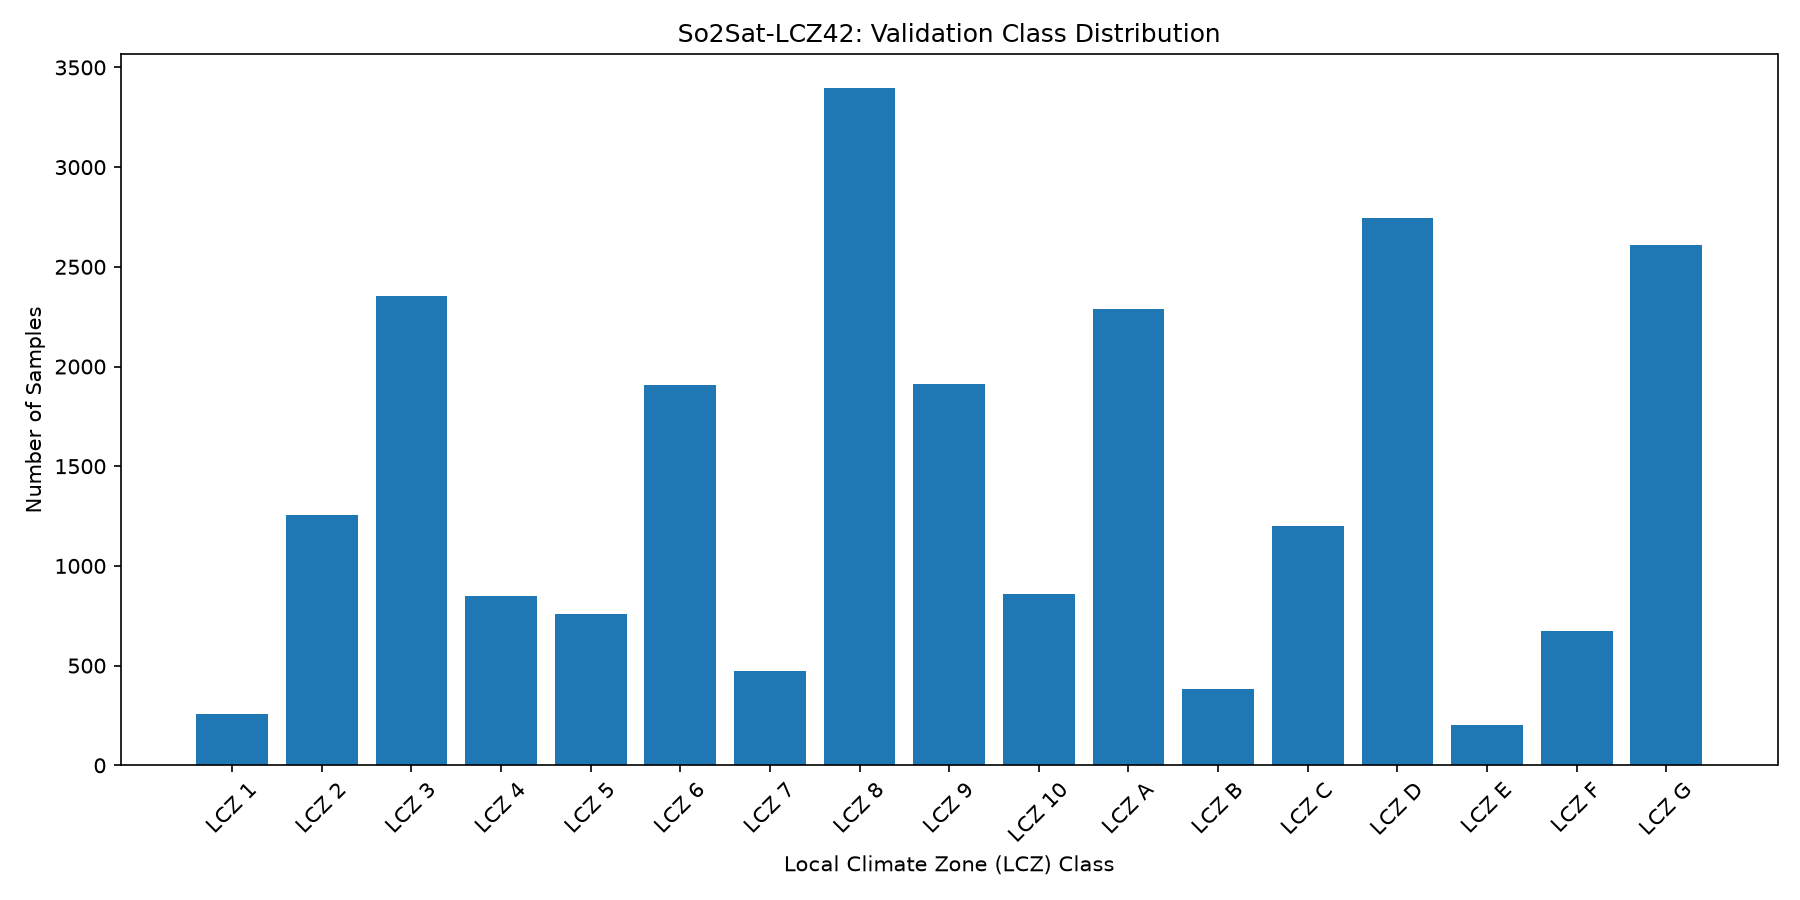

02 Class Percentages


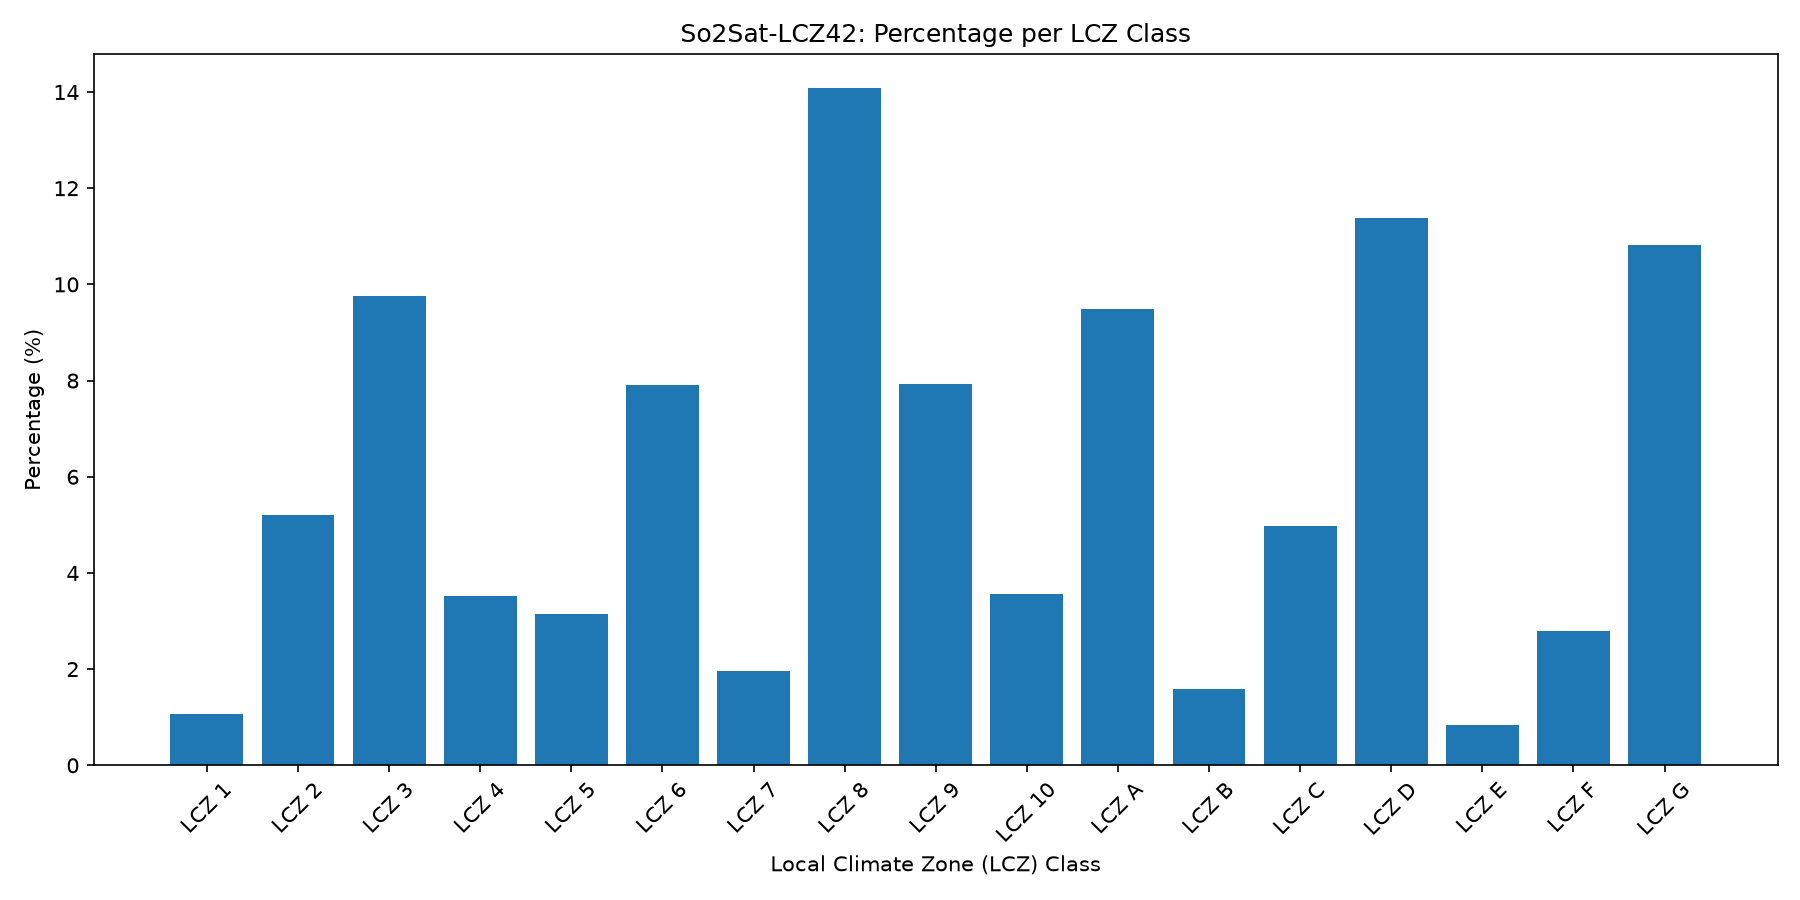

03 Class Imbalance


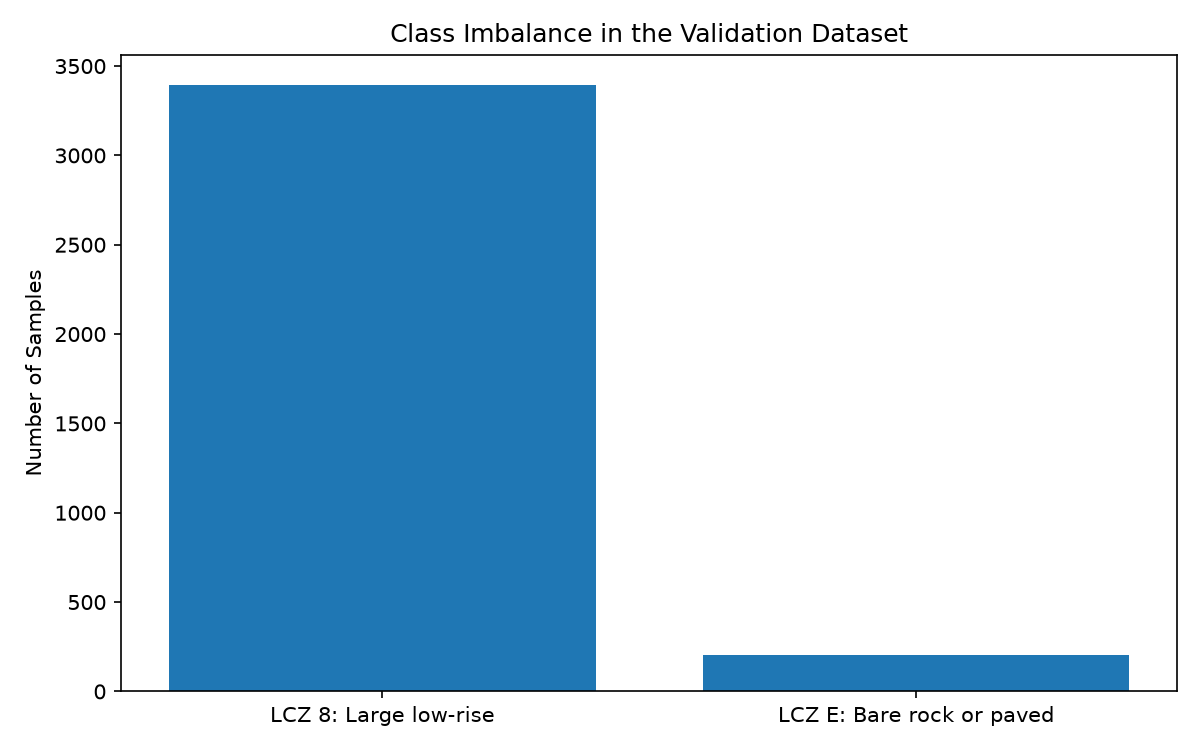

04 Sentinel1 Patch


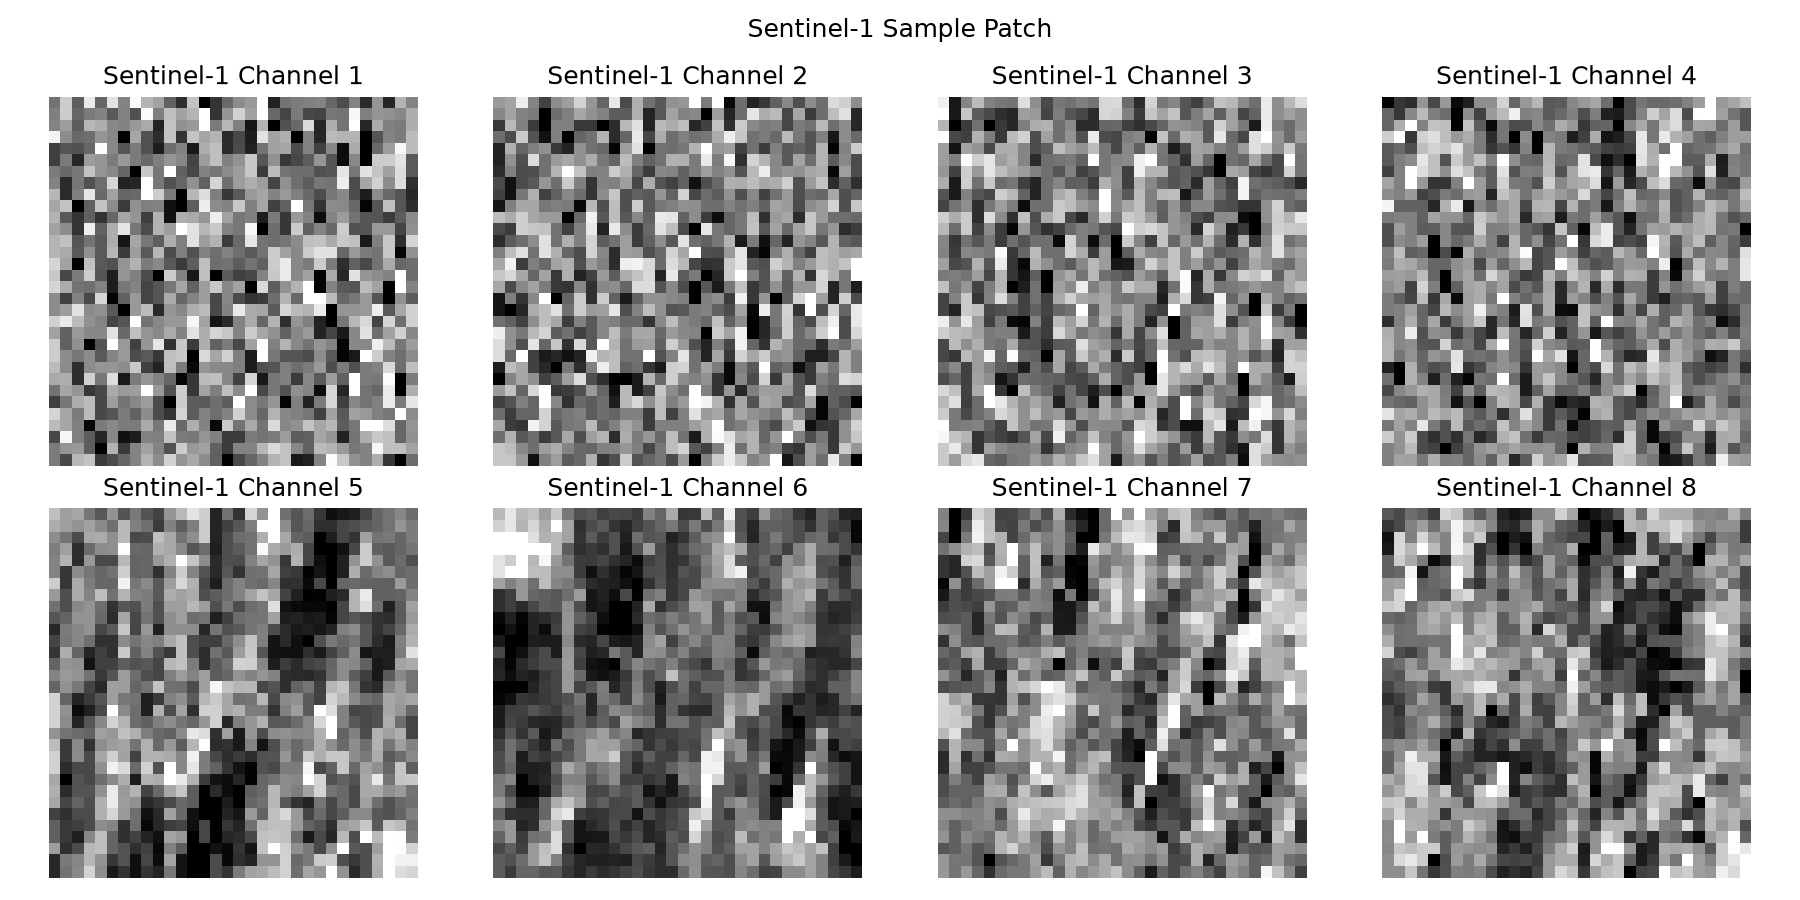

05 Sentinel2 Patch


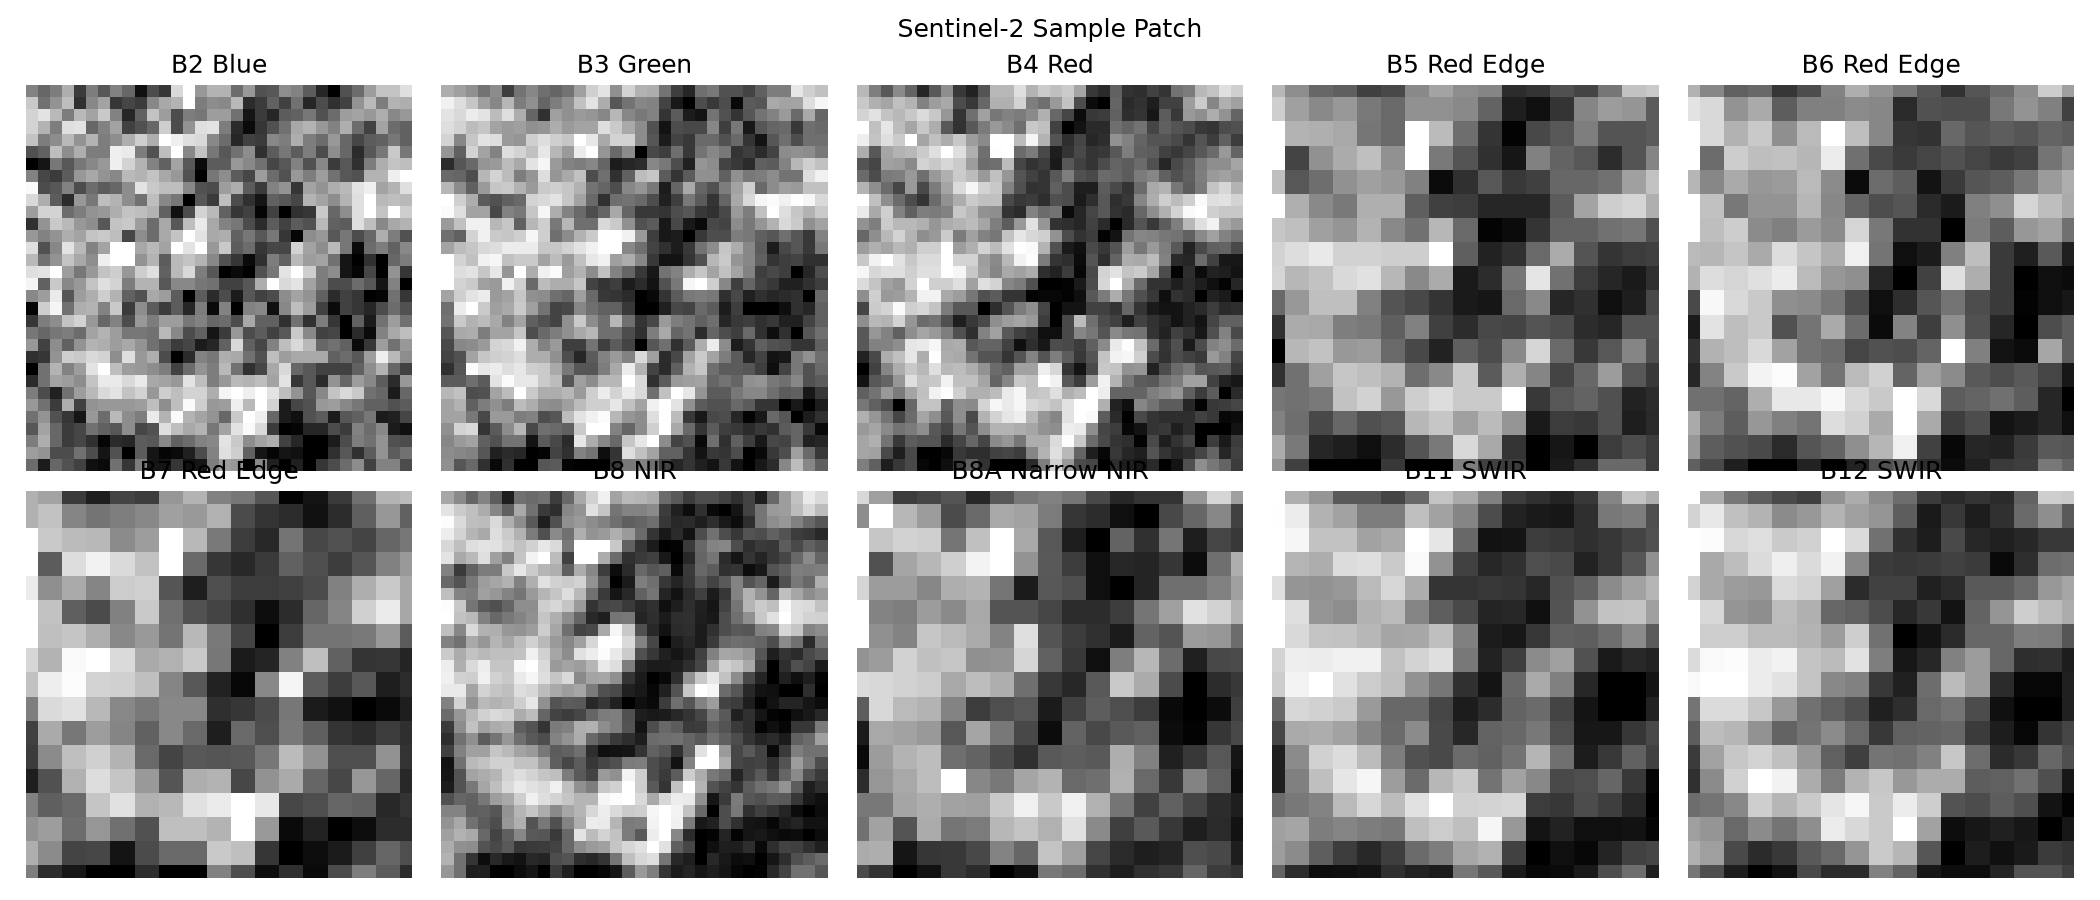

In [10]:
from IPython.display import display, Image
from pathlib import Path

# Find the project's graphs folder
candidates = [Path.cwd() / "graphs", Path.cwd().parent / "graphs"]
graph_dir = next(p for p in candidates if p.is_dir())

graph_files = [
    "01_class_distribution.png",
    "02_class_percentages.png",
    "03_class_imbalance.png",
    "04_sentinel1_patch.png",
    "05_sentinel2_patch.png"
]

for filename in graph_files:
    print(filename.replace("_", " ").replace(".png", "").title())
    display(Image(filename=str(graph_dir / filename)))

## 5. LCZ Class Distribution Analysis

This section calculates the number and percentage of validation samples belonging to each of the 17 LCZ classes. The results help identify differences in class representation and potential class imbalance.

## LCZ Class Mapping

The label vector contains 17 positions. The index of the active position identifies the Local Climate Zone (LCZ) class.

| Index | LCZ | Description |
|---:|---|---|
| 0 | LCZ 1 | Compact high-rise |
| 1 | LCZ 2 | Compact mid-rise |
| 2 | LCZ 3 | Compact low-rise |
| 3 | LCZ 4 | Open high-rise |
| 4 | LCZ 5 | Open mid-rise |
| 5 | LCZ 6 | Open low-rise |
| 6 | LCZ 7 | Lightweight low-rise |
| 7 | LCZ 8 | Large low-rise |
| 8 | LCZ 9 | Sparsely built |
| 9 | LCZ 10 | Heavy industry |
| 10 | LCZ A | Dense trees |
| 11 | LCZ B | Scattered trees |
| 12 | LCZ C | Bush, scrub |
| 13 | LCZ D | Low plants |
| 14 | LCZ E | Bare rock or paved |
| 15 | LCZ F | Bare soil or sand |
| 16 | LCZ G | Water |

## 6. Key Findings and Conclusion

### Key Findings
- The validation dataset contains 24,119 samples.
- Each sample has a 32 × 32 pixel patch.
- Sentinel-1 contains 8 channels, and Sentinel-2 contains 10 bands.
- The dataset represents 17 Local Climate Zone classes.
- No NaN values were detected in the labels or satellite data.
- LCZ 8 (Large low-rise) is the most frequent class, with 3,395 samples (14.08%).
- LCZ E (Bare rock or paved) is the least frequent class, with 202 samples (0.84%).
- The class distribution is imbalanced.

### Conclusion
The validation dataset was explored to understand its structure, data quality, class distribution, and satellite imagery. The visualizations and class mapping provide a foundation for the next stages of the project, including preprocessing, Quantum Support Vector Machine development, and model evaluation.

**Limitation:** This notebook reports dataset exploration results only; it does not measure model accuracy.

In [15]:
import h5py
import numpy as np

file_path = "../data/validation.h5"

with h5py.File(file_path, "r") as f:
    labels = f["label"][:]

class_labels = np.argmax(labels, axis=1)

print("Number of LCZ classes found:", len(np.unique(class_labels)))
print("LCZ class indices:", np.unique(class_labels))

Number of LCZ classes found: 17
LCZ class indices: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]


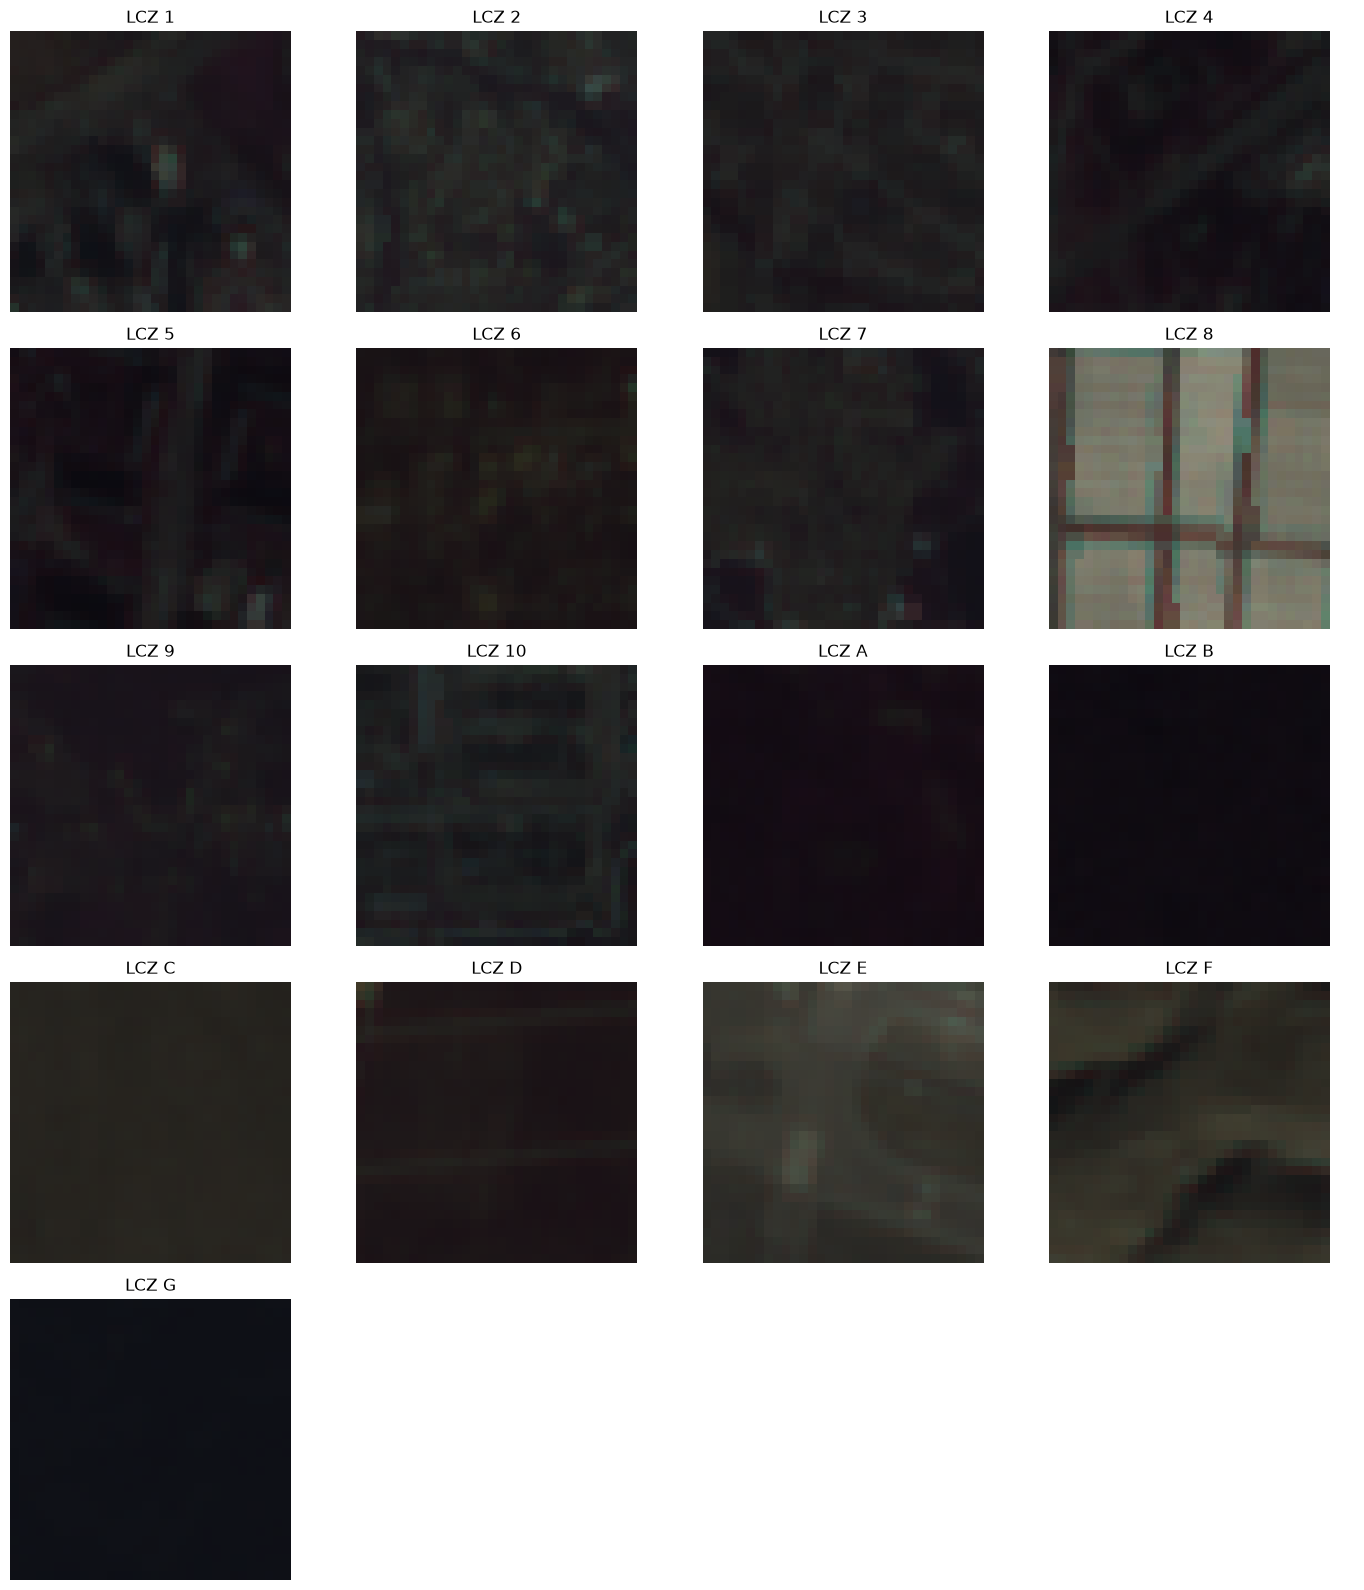

In [16]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

file_path = "../data/validation.h5"

class_names = [
    "LCZ 1", "LCZ 2", "LCZ 3", "LCZ 4", "LCZ 5",
    "LCZ 6", "LCZ 7", "LCZ 8", "LCZ 9", "LCZ 10",
    "LCZ A", "LCZ B", "LCZ C", "LCZ D", "LCZ E",
    "LCZ F", "LCZ G"
]

with h5py.File(file_path, "r") as f:
    labels = f["label"][:]
    sen2 = f["sen2"]

    class_labels = np.argmax(labels, axis=1)

    fig, axes = plt.subplots(5, 4, figsize=(14, 16))
    axes = axes.flatten()

    for class_id in range(17):
        sample_index = np.where(class_labels == class_id)[0][0]
        image = sen2[sample_index, :, :, :]

        # Display three bands as a false-colour image
        axes[class_id].imshow(image[:, :, [3, 2, 1]])
        axes[class_id].set_title(class_names[class_id])
        axes[class_id].axis("off")

    for i in range(17, len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.savefig("../graphs/06_all_17_lcz_classes.png",
                dpi=300, bbox_inches="tight")
    plt.show()

In [17]:
import os

output_path = "../graphs/06_all_17_lcz_classes.png"
print("File exists:", os.path.exists(output_path))
print("Saved location:", os.path.abspath(output_path))

File exists: True
Saved location: c:\Users\a\OneDrive\Pictures\Documents\Desktop\So2Sat_LCZ42_Project\graphs\06_all_17_lcz_classes.png


In [18]:
import h5py

file_path = "../data/validation.h5"

with h5py.File(file_path, "r") as f:
    for name in ["sen1", "sen2"]:
        print(f"\n{name}")
        print("Shape:", f[name].shape)
        print("Data type:", f[name].dtype)
        print("Attributes:", dict(f[name].attrs))


sen1
Shape: (24119, 32, 32, 8)
Data type: float64
Attributes: {}

sen2
Shape: (24119, 32, 32, 10)
Data type: float64
Attributes: {}


## Satellite Channel Information

### Sentinel-1 (sen1)
- Image shape: 32 × 32 pixels.
- Number of channels: 8.
- Data type: float64.
- Sentinel-1 provides Synthetic Aperture Radar (SAR) data.

### Sentinel-2 (sen2)
- Image shape: 32 × 32 pixels.
- Number of bands: 10.
- Data type: float64.
- Sentinel-2 provides multispectral optical data.

### Dataset Observation
The So2Sat-LCZ42 dataset combines Sentinel-1 SAR and Sentinel-2 multispectral data for Local Climate Zone classification across 17 classes.

The dataset contains 24,119 samples in the available validation file. The channel names, value ranges, and appropriate normalization method must be verified before preprocessing.

### Reference
So2Sat LCZ42: A Benchmark Data Set for the Classification of Global Local Climate Zones (2020), listed as Paper 1 in the project's literature review.

In [19]:
import gzip
import os

file_path = "../data/validation.h5.gz"

print("Compressed file exists:", os.path.exists(file_path))
print("Compressed file size (MB):",
      round(os.path.getsize(file_path) / (1024 * 1024), 2))

Compressed file exists: True
Compressed file size (MB): 1049.24


In [21]:
import h5py

files = [
    "../data/validation.h5",
    "../data/validation.h5.gz"
]

for path in files:
    try:
        with h5py.File(path, "r") as f:
            print("\nFile:", path)
            print("Sentinel-1 shape:", f["sen1"].shape)
            print("Sentinel-2 shape:", f["sen2"].shape)
            print("Label shape:", f["label"].shape)
    except Exception as e:
        print("\nFile:", path)
        print("Could not open directly:", e)


File: ../data/validation.h5
Sentinel-1 shape: (24119, 32, 32, 8)
Sentinel-2 shape: (24119, 32, 32, 10)
Label shape: (24119, 17)

File: ../data/validation.h5.gz
Could not open directly: Unable to synchronously open file (file signature not found)


In [22]:
import gzip

file_path = "../data/validation.h5.gz"

with gzip.open(file_path, "rb") as f:
    signature = f.read(8)

print("Decompressed file signature:", signature)
print("Is HDF5 format:", signature == b"\x89HDF\r\n\x1a\n")

Decompressed file signature: b'\x89HDF\r\n\x1a\n'
Is HDF5 format: True


In [23]:
import os

h5_size = os.path.getsize("../data/validation.h5")
gz_size = os.path.getsize("../data/validation.h5.gz")

print("HDF5 file size (MB):", round(h5_size / (1024 * 1024), 2))
print("GZ file size (MB):", round(gz_size / (1024 * 1024), 2))

HDF5 file size (MB): 3394.86
GZ file size (MB): 1049.24


In [24]:
import os

data_folder = "../data"

print("Files in data folder:")
for file in os.listdir(data_folder):
    print(file)

Files in data folder:
validation.h5
validation.h5.gz


In [25]:
import h5py
import numpy as np

with h5py.File("../data/validation.h5", "r") as f:
    labels = f["label"][:]
    class_labels = np.argmax(labels, axis=1)

print("Total samples:", len(class_labels))
print("Number of classes:", len(np.unique(class_labels)))
print("All 17 classes present:", len(np.unique(class_labels)) == 17)

Total samples: 24119
Number of classes: 17
All 17 classes present: True


In [26]:
import h5py
import numpy as np

with h5py.File("../data/validation.h5", "r") as f:
    for name in ["sen1", "sen2", "label"]:
        data = f[name]
        nan_count = 0
        inf_count = 0

        for start in range(0, data.shape[0], 500):
            batch = data[start:start + 500]
            nan_count += np.isnan(batch).sum()
            inf_count += np.isinf(batch).sum()

        print(f"{name}: NaN = {nan_count}, Inf = {inf_count}")

sen1: NaN = 0, Inf = 0
sen2: NaN = 0, Inf = 0
label: NaN = 0, Inf = 0


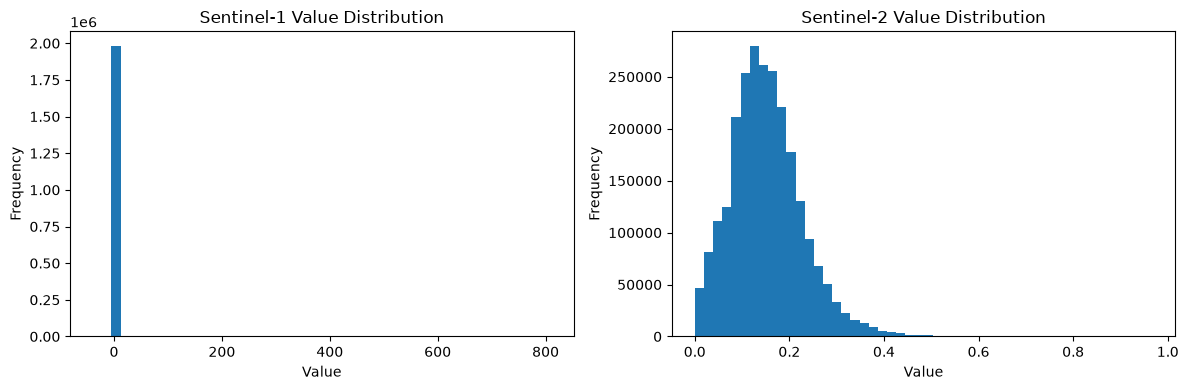

In [27]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

with h5py.File("../data/validation.h5", "r") as f:
    sen1 = f["sen1"][::100].ravel()
    sen2 = f["sen2"][::100].ravel()

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(sen1, bins=50)
plt.title("Sentinel-1 Value Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(sen2, bins=50)
plt.title("Sentinel-2 Value Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()



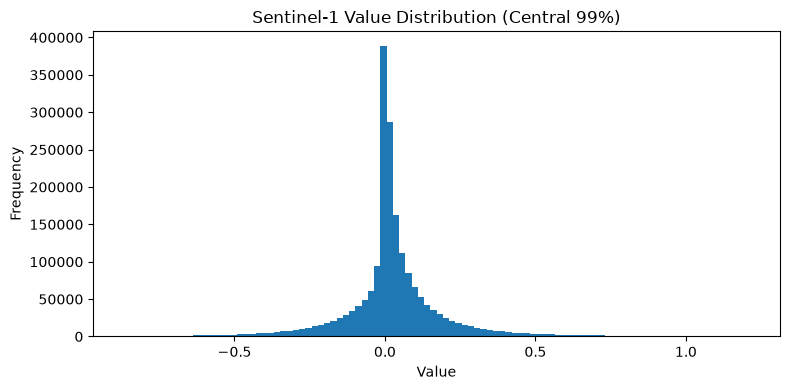

0.5th percentile: -0.8657084140181541
99.5th percentile: 1.208991152644162


In [28]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

with h5py.File("../data/validation.h5", "r") as f:
    sen1 = f["sen1"][::100].ravel()

# Focus on the central 99% of values for visualization
low, high = np.percentile(sen1, [0.5, 99.5])

plt.figure(figsize=(8, 4))
plt.hist(sen1, bins=100, range=(low, high))
plt.title("Sentinel-1 Value Distribution (Central 99%)")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("0.5th percentile:", low)
print("99.5th percentile:", high)

In [29]:
import h5py
import numpy as np

with h5py.File("../data/validation.h5", "r") as f:
    sen1 = f["sen1"]

    print("Sentinel-1 channel statistics:")
    for channel in range(sen1.shape[-1]):
        values = sen1[::100, :, :, channel].ravel()

        print(
            f"Channel {channel + 1}: "
            f"min={values.min():.4f}, "
            f"max={values.max():.4f}, "
            f"mean={values.mean():.4f}, "
            f"std={values.std():.4f}"
        )

Sentinel-1 channel statistics:
Channel 1: min=-8.9993, max=7.4579, mean=-0.0004, std=0.1748
Channel 2: min=-7.2105, max=5.4287, mean=0.0003, std=0.1706
Channel 3: min=-37.0087, max=27.6698, mean=-0.0006, std=0.4512
Channel 4: min=-28.4674, max=35.6563, mean=-0.0017, std=0.4505
Channel 5: min=0.0005, max=46.5073, mean=0.0442, std=0.2473
Channel 6: min=0.0008, max=809.7129, mean=0.2546, std=3.6372
Channel 7: min=-38.8074, max=47.9152, mean=0.0006, std=0.2622
Channel 8: min=-26.4616, max=110.8162, mean=0.0007, std=0.3405


In [30]:
import h5py
import numpy as np

with h5py.File("../data/validation.h5", "r") as f:
    sen2 = f["sen2"]

    print("Sentinel-2 channel statistics:")
    for channel in range(sen2.shape[-1]):
        values = sen2[::100, :, :, channel].ravel()

        print(
            f"Channel {channel + 1}: "
            f"min={values.min():.4f}, "
            f"max={values.max():.4f}, "
            f"mean={values.mean():.4f}, "
            f"std={values.std():.4f}"
        )



Sentinel-2 channel statistics:
Channel 1: min=0.0350, max=0.6344, mean=0.1267, std=0.0364
Channel 2: min=0.0415, max=0.6801, mean=0.1141, std=0.0408
Channel 3: min=0.0230, max=0.8574, mean=0.1089, std=0.0557
Channel 4: min=0.0197, max=0.5262, mean=0.1220, std=0.0509
Channel 5: min=0.0168, max=0.5470, mean=0.1680, std=0.0623
Channel 6: min=0.0142, max=0.5900, mean=0.1911, std=0.0744
Channel 7: min=0.0115, max=0.9679, mean=0.1840, std=0.0771
Channel 8: min=0.0089, max=0.6143, mean=0.2062, std=0.0837
Channel 9: min=0.0014, max=0.8025, mean=0.1730, std=0.0878
Channel 10: min=0.0001, max=0.9226, mean=0.1245, std=0.0793


## Channel-Wise Statistical Analysis

### Sentinel-1
- The 8 channels have different value ranges and standard deviations.
- Channel 6 has the largest observed maximum (809.7129) and standard deviation (3.6372) in the sampled images.
- Most channel means are close to zero.

### Sentinel-2
- The 10 channels have different value ranges and standard deviations.
- Observed channel means range from approximately 0.1089 to 0.2062.
- Observed standard deviations range from approximately 0.0364 to 0.0878.

### Conclusion
Channel-wise statistics show that the two satellite modalities have different numerical distributions. These findings should be considered when selecting preprocessing and normalization methods. The statistics above were calculated from every 100th image in the validation dataset, so they are sample-based estimates rather than full-dataset statistics.

## Dataset Split Status

- Available local split: Validation (`validation.h5`)
- Number of validation samples: 24,119
- Training dataset: Not yet located in the project folder
- Test dataset: Not yet located in the project folder

### Next Action
Locate the training and test datasets required for model development and evaluation before implementing the final preprocessing pipeline.

## Proposed Preprocessing Pipeline

1. **Load the data:** Read Sentinel-1, Sentinel-2, and LCZ labels from the HDF5 files.
2. **Validate the data:** Check shapes, data types, missing values, and invalid values.
3. **Prepare labels:** Convert the 17-class one-hot labels into integer class indices when required by the model.
4. **Normalize the data:** Select a suitable normalization method after confirming the dataset's original preprocessing and the training data availability.
5. **Prepare model inputs:** Preserve Sentinel-1 and Sentinel-2 as separate modalities until the model's input requirements are confirmed.
6. **Prepare data splits:** Use separate training, validation, and test datasets when available.
7. **Prepare tensors:** Convert the preprocessed data into the shapes and data types required by each model.

### Important Note
The final normalization parameters must be determined using training data only. The validation and test sets must not be used to fit those parameters.

In [32]:
from pathlib import Path

file_path = Path("../data/testing.h5.gz")

if file_path.exists():
    size_bytes = file_path.stat().st_size
    print("File size in bytes:", size_bytes)
    print("File size in MB:", round(size_bytes / (1024**2), 2))
else:
    print("File not found")

File size in bytes: 1100520239
File size in MB: 1049.54


In [33]:
import gzip

file_path = "../data/testing.h5.gz"

try:
    with gzip.open(file_path, "rb") as f:
        header = f.read(8)

    print("HDF5 file signature:", header)
    print("Looks like HDF5:", header == b"\x89HDF\r\n\x1a\n")

except Exception as e:
    print("Verification failed:", e)

HDF5 file signature: b'\x89HDF\r\n\x1a\n'
Looks like HDF5: True


In [34]:
import gzip
import h5py

file_path = "../data/testing.h5.gz"

with gzip.open(file_path, "rb") as compressed_file:
    with h5py.File(compressed_file, "r") as f:
        print("Datasets:", list(f.keys()))

        for key in f.keys():
            print(key, f[key].shape, f[key].dtype)

Datasets: ['label', 'sen1', 'sen2']
label (24188, 17) float64
sen1 (24188, 32, 32, 8) float64
sen2 (24188, 32, 32, 10) float64


### Dataset Split

The So2Sat-LCZ42 dataset contains 400,673 samples divided into three geographically separated subsets:

- **Training:** 352,366 samples
- **Validation:** 24,119 samples
- **Testing:** 24,188 samples

The training set will be used to calculate normalization statistics. The same statistics will then be applied to the validation and testing sets to avoid data leakage.

In [40]:

import numpy as np

def preprocess_batch(
    sen1, sen2, labels,
    sen1_mean=None, sen1_std=None,
    sen2_mean=None, sen2_std=None
):
    sen1 = np.asarray(sen1, dtype=np.float32)
    sen2 = np.asarray(sen2, dtype=np.float32)
    labels = np.asarray(labels)

    labels = np.argmax(labels, axis=1).astype(np.int64)

    if sen1_mean is not None and sen1_std is not None:
        sen1 = (sen1 - sen1_mean) / np.maximum(sen1_std, 1e-6)

    if sen2_mean is not None and sen2_std is not None:
        sen2 = (sen2 - sen2_mean) / np.maximum(sen2_std, 1e-6)

    sen1 = np.transpose(sen1, (0, 3, 1, 2))
    sen2 = np.transpose(sen2, (0, 3, 1, 2))

    return sen1, sen2, labels


In [41]:

# Test preprocessing with 4 samples from the testing dataset
import h5py
import gzip
import numpy as np

with gzip.open("../data/testing.h5.gz", "rb") as f:
    with h5py.File(f, "r") as h5:
        sen1 = h5["sen1"][:4]
        sen2 = h5["sen2"][:4]
        labels = h5["label"][:4]

s1, s2, y = preprocess_batch(sen1, sen2, labels)

print("Sentinel-1:", s1.shape)
print("Sentinel-2:", s2.shape)
print("Labels:", y.shape)
print("Label IDs:", y)


Sentinel-1: (4, 8, 32, 32)
Sentinel-2: (4, 10, 32, 32)
Labels: (4,)
Label IDs: [16  9  8 16]


### Sentinel-1 and Sentinel-2 Model Input

Sentinel-1 and Sentinel-2 are preprocessed separately. Sentinel-1 produces tensors of shape `(N, 8, 32, 32)`, while Sentinel-2 produces tensors of shape `(N, 10, 32, 32)`. Both modalities use `float32`, and labels are converted to integer class IDs from 0 to 16.

The two modalities will remain separate until the Transformer architecture and fusion strategy are confirmed with the project team. Normalization statistics must be calculated using the training dataset only and reused for validation and testing.

### Train, Validation, and Test Split Handling

- **Training set:** Used to train the model and calculate normalization statistics.
- **Validation set:** Used to evaluate model performance during development and tune model settings.
- **Testing set:** Reserved for final evaluation after model development.

Normalization statistics must be calculated using the training set only and reused for validation and testing. The training dataset is not currently available locally, so training-based normalization statistics remain pending.

### Final Normalization Procedure

1. Convert Sentinel-1 and Sentinel-2 image data to `float32`.
2. Calculate the mean and standard deviation for each channel using the training dataset only.
3. Normalize each channel using `(value - mean) / standard deviation`, with a small positive lower bound on the standard deviation to avoid division by zero.
4. Apply the same training-derived statistics to the validation and testing datasets.
5. Convert image tensors from `(N, 32, 32, C)` to `(N, C, 32, 32)`.
6. Convert one-hot labels to integer class IDs from 0 to 16.

**Status:** The preprocessing function supports normalization, tensor conversion, and label conversion. Training-derived normalization statistics have not yet been calculated because the training dataset is unavailable locally.

In [42]:

import numpy as np

def preprocess_batch(
    sen1, sen2, labels,
    sen1_mean=None, sen1_std=None,
    sen2_mean=None, sen2_std=None
):
    sen1 = np.asarray(sen1, dtype=np.float32)
    sen2 = np.asarray(sen2, dtype=np.float32)
    labels = np.asarray(labels)

    labels = np.argmax(labels, axis=1).astype(np.int64)

    if sen1_mean is not None and sen1_std is not None:
        sen1 = (sen1 - sen1_mean) / np.maximum(sen1_std, 1e-6)

    if sen2_mean is not None and sen2_std is not None:
        sen2 = (sen2 - sen2_mean) / np.maximum(sen2_std, 1e-6)

    sen1 = np.transpose(sen1, (0, 3, 1, 2))
    sen2 = np.transpose(sen2, (0, 3, 1, 2))

    return sen1, sen2, labels


In [43]:

# Quick test of preprocessing and normalization
import numpy as np

# Four synthetic samples, with 8 Sentinel-1 and 10 Sentinel-2 channels
test_sen1 = np.ones((4, 32, 32, 8), dtype=np.float64)
test_sen2 = np.ones((4, 32, 32, 10), dtype=np.float64)

test_labels = np.eye(17)[[0, 3, 8, 16]]

# Use synthetic channel statistics just to test the function
s1_mean = np.zeros(8, dtype=np.float32)
s1_std = np.ones(8, dtype=np.float32)
s2_mean = np.zeros(10, dtype=np.float32)
s2_std = np.ones(10, dtype=np.float32)

s1, s2, y = preprocess_batch(
    test_sen1, test_sen2, test_labels,
    s1_mean, s1_std, s2_mean, s2_std
)

print("Sentinel-1 shape:", s1.shape)
print("Sentinel-2 shape:", s2.shape)
print("Labels:", y)
print("Data types:", s1.dtype, s2.dtype, y.dtype)
print("Normalization test:", np.allclose(s1, 1.0) and np.allclose(s2, 1.0))


Sentinel-1 shape: (4, 8, 32, 32)
Sentinel-2 shape: (4, 10, 32, 32)
Labels: [ 0  3  8 16]
Data types: float32 float32 int64
Normalization test: True
